# Double-well potential

$$dX_t=(0.5X_t-X_t^3)\,dt+(1+0.25X_t^2)\,dB_t^P.$$

Repeat the Black-Scholes workflow with $N=100000$, $T=1$, $X_0=1$, and seed 3.
Compare Method 1, Method 2, and ODE2 for drift. Use Method 1 for noise recovery
and the final SSISDE fit, as in Black-Scholes. Only the diffusion regression
parameters are tuned. ODE2 uses the known initial spatial slope.


In [1]:
from pathlib import Path
import os
import sys

if not (3, 10) <= sys.version_info[:2] < (3, 13):
    raise RuntimeError("The original dependency pins require Python 3.10–3.12; use the local .venv or a compatible Colab runtime.")

def _find_project():
    for candidate in [Path.cwd(), *Path.cwd().parents, Path('/content/SSISDE')]:
        if (candidate / 'models/stochastic_sindy.py').is_file() and (candidate / 'requirements.txt').is_file():
            return candidate
    return None

PROJECT_ROOT = _find_project()
if PROJECT_ROOT is None:
    import importlib.util
    try:
        _in_colab = importlib.util.find_spec('google.colab') is not None
    except ModuleNotFoundError:
        _in_colab = False
    if not _in_colab:
        raise FileNotFoundError("Open this notebook from the SSISDE checkout so its Python scripts are available.")

    def _download_private_project():
        from getpass import getpass
        from io import BytesIO
        from urllib.request import Request, urlopen
        from zipfile import ZipFile
        token = getpass('GitHub token (read-only Contents access to SSISDE): ')
        try:
            request = Request(
                'https://api.github.com/repos/munawarali93/SSISDE/zipball/main',
                headers={'Authorization': f'Bearer {token}', 'Accept': 'application/vnd.github+json'},
            )
            with urlopen(request, timeout=120) as response:
                archive_bytes = response.read()
        finally:
            token = None
            request = None
        destination = Path('/content/SSISDE')
        with ZipFile(BytesIO(archive_bytes)) as archive:
            for member in archive.infolist():
                relative = Path(*Path(member.filename).parts[1:])
                if member.is_dir() or not relative.parts:
                    continue
                target = (destination / relative).resolve()
                if not target.is_relative_to(destination.resolve()):
                    raise ValueError('Unsafe archive path')
                target.parent.mkdir(parents=True, exist_ok=True)
                target.write_bytes(archive.read(member))
        return destination

    PROJECT_ROOT = _download_private_project()

os.chdir(PROJECT_ROOT / 'experiments/double_well')
print(f'Project: {PROJECT_ROOT}')
print(f'Python: {sys.version.split()[0]}')

sys.path.insert(0, str(PROJECT_ROOT))
RESULTS = PROJECT_ROOT / 'outputs/double_well'
RESULTS.mkdir(parents=True, exist_ok=True)


Project: /Users/munawarali/Documents/GitHub/SSISDE
Python: 3.11.13


##Install libraries

In [2]:
# Install into the selected kernel before importing scientific libraries.
# The four original version pins are retained in requirements.txt.
import subprocess
subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-r', str(PROJECT_ROOT / 'requirements.txt')])



[notice] A new release of pip is available: 25.1.1 -> 26.2.1
[notice] To update, run: /Users/munawarali/Documents/GitHub/SSISDE/.venv/bin/python -m pip install --upgrade pip


0

##Import libraries

In [3]:
import numpy as np
import math
import matplotlib.pyplot as plt
import pysindy as ps
import random
import iisignature
from sklearn import linear_model
from sklearn.metrics import mean_squared_error
from tqdm import tqdm
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.model_selection import TimeSeriesSplit
import json
from threadpoolctl import threadpool_limits
from models.diffusion_tuning import fit_diffusion


/Users/munawarali/Documents/GitHub/SSISDE/.venv/lib/python3.11/site-packages/pysindy/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound


##Defining parameters and simulating noise

In [4]:
from data_generation.double_well import generate_data
N, T, S0, seed = 100000, 1.0, 1.0, 3
t, dt, S_, W_, mu_exact_, sigma_exact_ = generate_data(N, T, S0, seed)
fine_dt = dt


##Simulating primary processes

## $$dS_t = \mu(S_t)dt + \sigma(S_t)dB_t$$

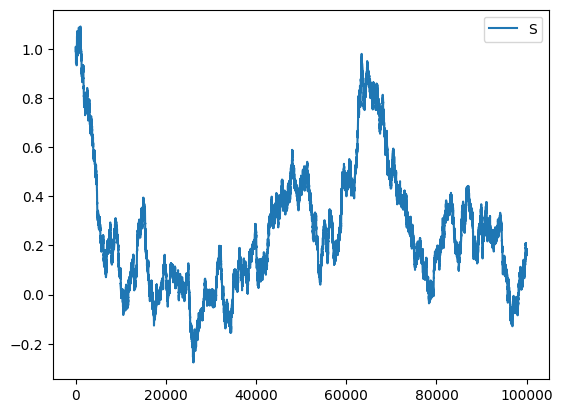

In [5]:
plt.plot(S_, label="S")
plt.legend()
plt.show()

##compute quadratic variation

  0%|          | 0/100000 [00:00<?, ?it/s]

 13%|█▎        | 13489/100000 [00:00<00:00, 134873.73it/s]

 27%|██▋       | 26977/100000 [00:00<00:00, 87162.82it/s] 

 37%|███▋      | 36641/100000 [00:00<00:00, 67353.27it/s]

 44%|████▍     | 44125/100000 [00:00<00:00, 56497.54it/s]

...

 92%|█████████▏| 92072/100000 [00:02<00:00, 22132.18it/s]

 94%|█████████▍| 94266/100000 [00:02<00:00, 21513.41it/s]

 96%|█████████▋| 96402/100000 [00:02<00:00, 20975.29it/s]

 98%|█████████▊| 98487/100000 [00:02<00:00, 20497.76it/s]

100%|██████████| 100000/100000 [00:02<00:00, 34417.74it/s]

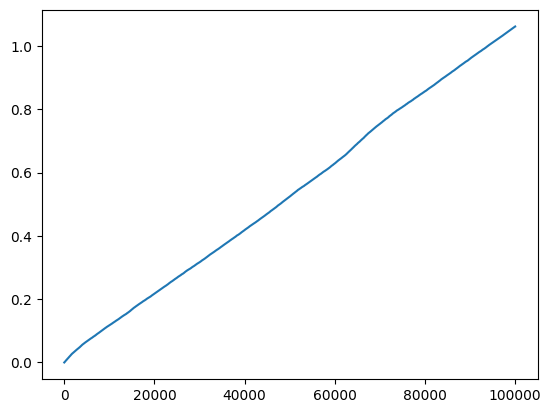

In [6]:
from models.quadratic_variation import estimate_quadratic_variation
QV, dQV, diff_method = estimate_quadratic_variation(S_, t)
plt.plot(QV)

## Approximating $\sigma$

Use the existing degree-4 variance library. Select SR3 settings on the last
20% of observations, then refit on the full path. The true diffusion is used
only to report error. All subsequent stages follow Black-Scholes.

In [7]:
thresholds = [0.01, 0.1, 0.3, 1.0, 3.0, 10.0]
nus = [0.1, 0.5, 2.0]
model, sigma_settings, sigma_search = fit_diffusion(S_, t, dQV, thresholds, nus)
sigma_equation = model.equations(precision=8)[0]
print('sigma^2(X) =', sigma_equation)
print(sigma_settings)
(RESULTS / 'diffusion_tuning.json').write_text(json.dumps(sigma_search, indent=2))

sigma^2(X) = 0.98821428 1 + 0.02488806 X + 0.51636376 X^2
{'threshold': 3.0, 'nu': 0.5, 'validation_mse': 1.729465164559883, 'max_iter': 10000, 'tol': 1e-08, 'terms': 3, 'converged': True, 'full_fit_converged': True}


3005

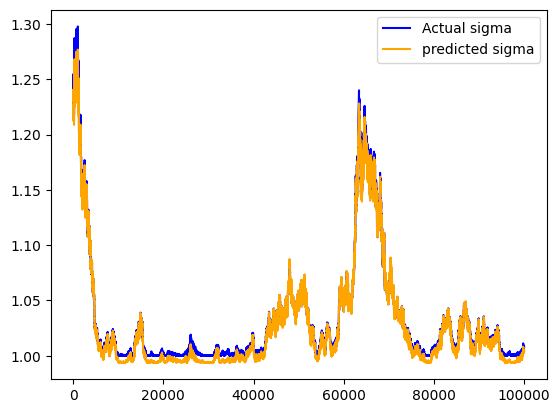

In [8]:
sigma_pred_ = np.sqrt(model.predict(S_.reshape(-1, 1)))
sigma_pred_ = np.array(sigma_pred_)
plt.plot(sigma_exact_, label="Actual sigma",color="blue")
plt.plot(sigma_pred_,label="predicted sigma", color="orange")
plt.legend()
plt.show()

In [9]:
from models.diffusion_derivatives import diffusion_derivatives
sigma_prime_, sigma_2prime_, sigma_3prime_ = diffusion_derivatives(sigma_pred_, S_, diff_method)


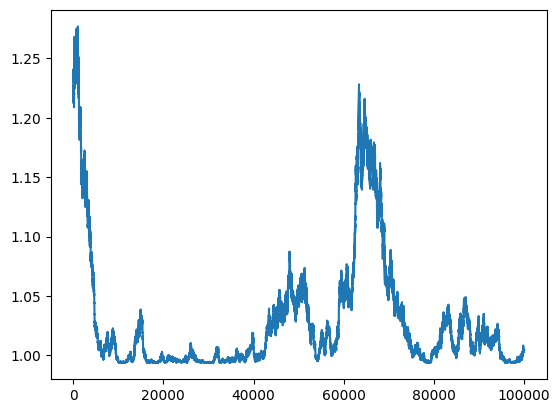

In [10]:
plt.plot(sigma_pred_)

##Q Brownian motion

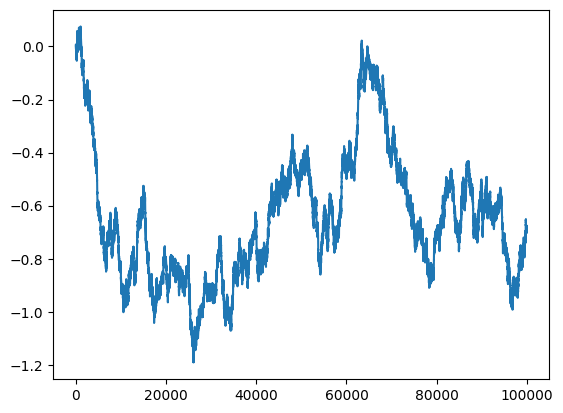

In [11]:
from models.q_brownian_motion import recover_q_noise
BQ_ = recover_q_noise(S_, sigma_pred_)
plt.plot(BQ_)

#Fit signature model

In [12]:
keep_cols = [0, 1, 3, 4, 5, 13]

  0%|          | 0/1000 [00:00<?, ?it/s]

 20%|██        | 201/1000 [00:00<00:00, 2002.15it/s]

 40%|████      | 402/1000 [00:00<00:00, 2005.08it/s]

 60%|██████    | 603/1000 [00:00<00:00, 2006.24it/s]

 81%|████████  | 808/1000 [00:00<00:00, 2022.92it/s]

100%|██████████| 1000/1000 [00:00<00:00, 2016.84it/s]

0.00011674972607588812

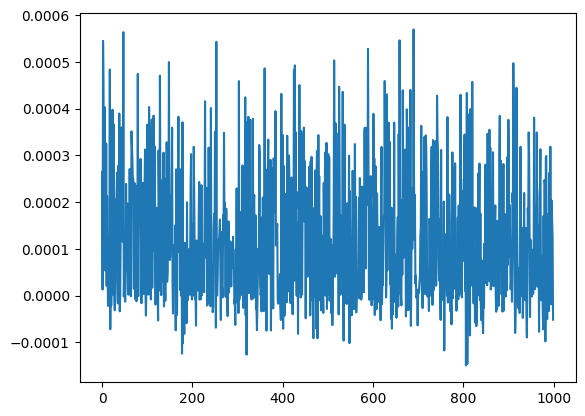

In [13]:
from models.signature_regression import fit_signature
M = 100
K = int(N/M)
l21 = fit_signature(S_, BQ_, t, keep_cols, M)
plt.plot(l21)
np.mean(l21)

In [14]:
from data_generation.coarse_graining import coarse_grain
sigma_pred, mu_exact, S, BQ, W, sigma_exact = coarse_grain(
    S_, BQ_, W_, mu_exact_, sigma_exact_, sigma_pred_, M, K,
)


In [15]:
from models.coarse_diffusion_derivatives import coarse_diffusion_derivatives
sigma_prime, sigma_2prime, sigma_3prime = coarse_diffusion_derivatives(sigma_pred, S, diff_method)


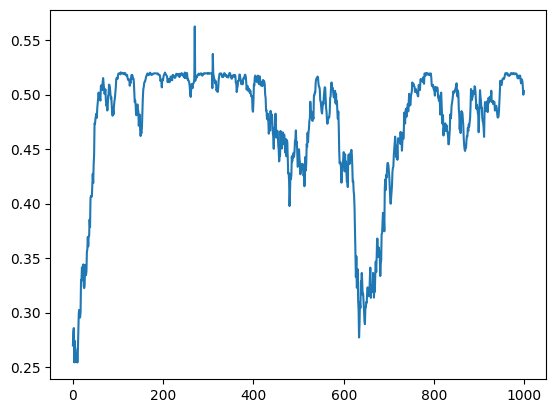

In [16]:
plt.plot(sigma_2prime)

## Predicting $\mu(X_t)$ by tuncating up to level-2 of iterated integrals

In [17]:
from models.drift_coefficients import drift_coefficients
mu_0, a, b, b_ = drift_coefficients(mu_exact, sigma_pred, sigma_prime, sigma_2prime, l21)


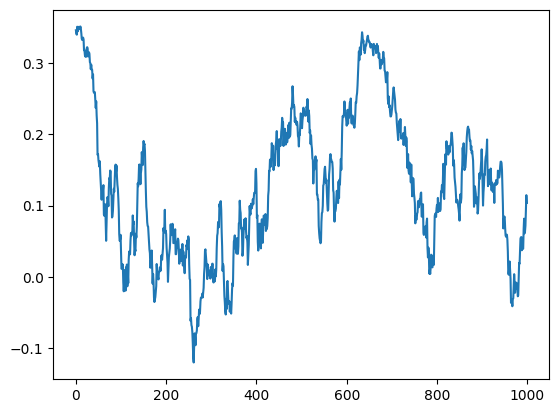

In [18]:
#plt.plot(b)
plt.plot(a)

In [19]:
from models.drift_recovery import recover_drift
mu_pred1, mu_pred2 = recover_drift(S, a, b, b_, mu_0)


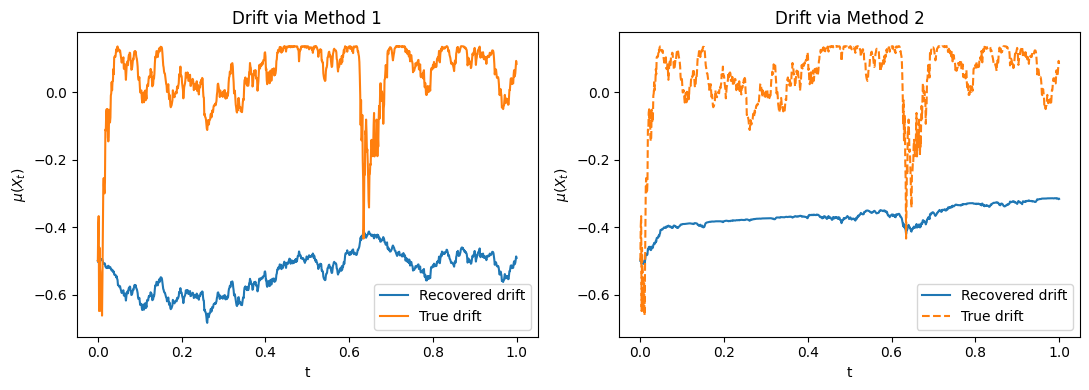

In [20]:
t_ = np.linspace(0, T, K)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(t_, mu_pred1, label="Recovered drift")
axes[0].plot(t_, mu_exact, label="True drift")
axes[0].set_title("Drift via Method 1")
axes[0].set_xlabel("t")
axes[0].set_ylabel("$\mu(X_t)$")
axes[0].legend()
axes[1].plot(t_, mu_pred2, label="Recovered drift")
axes[1].set_title("Drift via Method 2")
axes[1].plot(t_, mu_exact, '--', label="True drift")
axes[1].set_xlabel("t")
axes[1].set_ylabel("$\mu(X_t)$")
axes[1].legend()
axes[1].set_ylim(axes[0].get_ylim())

plt.tight_layout()
plt.savefig("Drift_via_Euler_BS.png", bbox_inches='tight', dpi=300)
plt.show()

## Drift recovery from ODE2

Use the same ODE2 recurrence as Black-Scholes. Supply the initial drift and
the known initial spatial slope for this process. This is a drift comparison;
noise recovery below uses Method 1.

In [21]:
lambda_0 = 0.5 - 3*S0**2
from models.drift_recovery_from_ODE2 import recover_drift_ode2
mu_pred11, lamda_pred = recover_drift_ode2(S, sigma_pred, sigma_prime, sigma_2prime, mu_0, lambda_0)


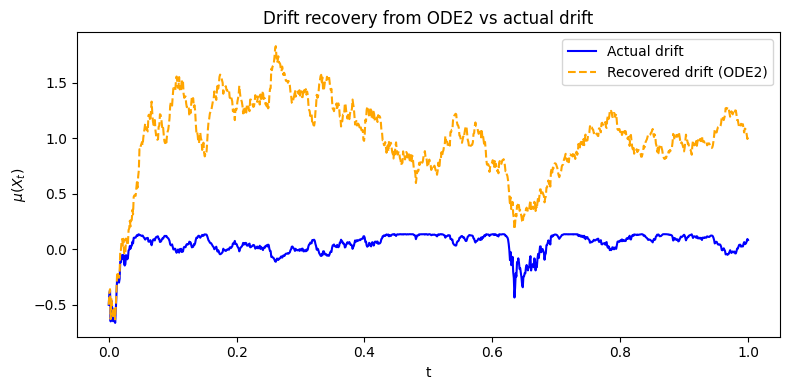

ODE2 drift MSE: 1.03015
ODE2 drift RMSE: 1.01496


In [22]:
plt.figure(figsize=(8, 4))
plt.plot(t_, mu_exact, label="Actual drift", color="blue")
plt.plot(t_, mu_pred11, '--', label="Recovered drift (ODE2)", color="orange")
plt.xlabel("t")
plt.ylabel(r"$\mu(X_t)$")
plt.title("Drift recovery from ODE2 vs actual drift")
plt.legend()
plt.tight_layout()
plt.savefig("Drift_via_ODE2_BS.png", bbox_inches='tight', dpi=300)
plt.show()

ode2_drift_mse = mean_squared_error(mu_exact, mu_pred11)
print(f"ODE2 drift MSE: {ode2_drift_mse:.6g}")
print(f"ODE2 drift RMSE: {np.sqrt(ode2_drift_mse):.6g}")


##Predicting P-Brownian motion

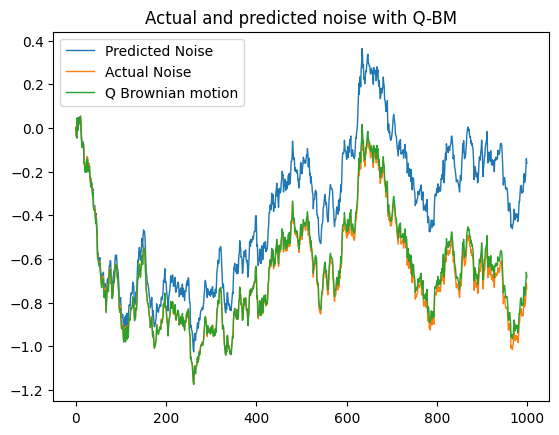

In [23]:
from models.p_brownian_motion import recover_p_noise
model = "Psi_approx_BS"
BP, dt, t = recover_p_noise(BQ, mu_pred1, sigma_pred, T)
plt.plot(BP, label="Predicted Noise", linewidth=1)
plt.plot(W, label="Actual Noise", linewidth=1)
plt.plot(BQ, label="Q Brownian motion", linewidth=1)
plt.title("Actual and predicted noise with Q-BM")
plt.legend()
plt.savefig(f"{model}_Actual and predicted noise with Q-BM.png", bbox_inches='tight', dpi=300)
plt.show()

MSE: 3.343e-08
μ(X) = -0.523664
σ(X) = 0.993702 + 0.019956*X + 0.226928*X^2
[CV best] alpha=0.00131, l1_ratio (rho)=0.40


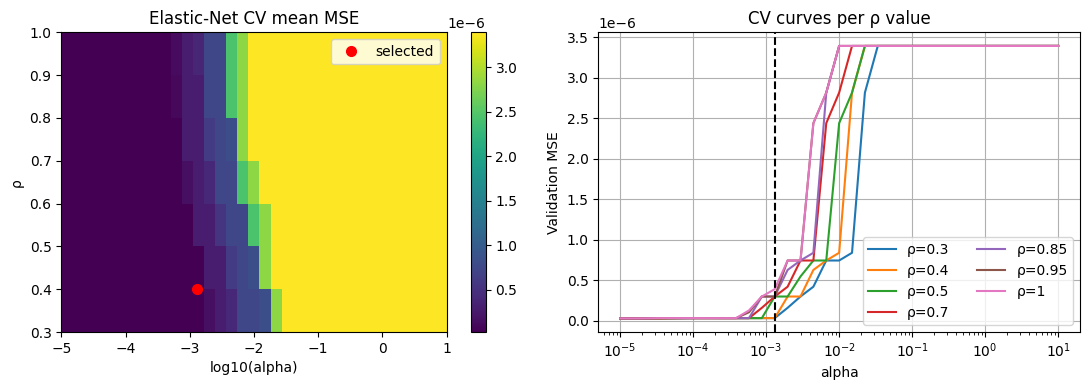

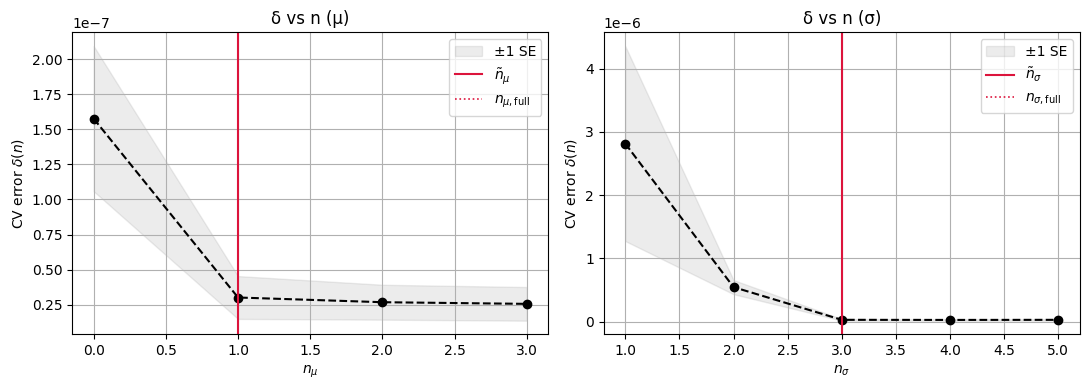

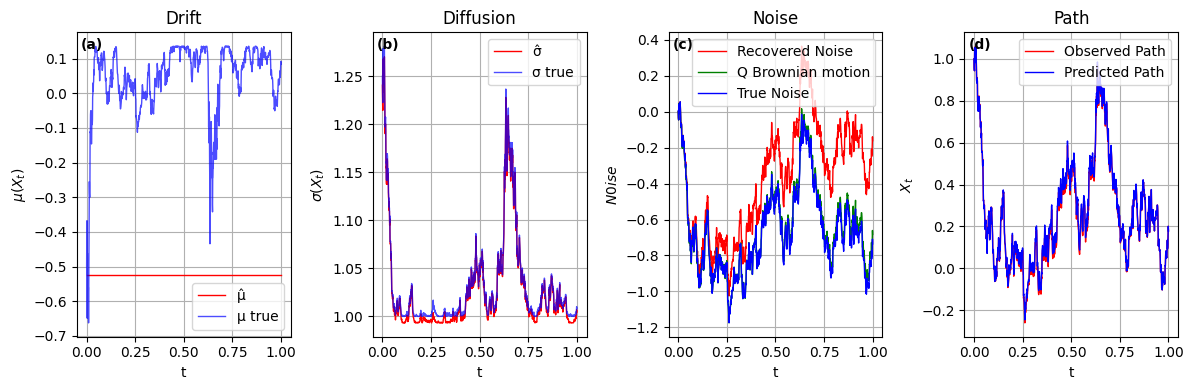

In [24]:
from models.stochastic_sindy import StochSINDy
identifier = StochSINDy(
    mu_deg=5, si_deg=5,
    pen="elasticnet",
    use_cv=True, k=7,
    alphas=np.geomspace(1e-5, 1e1, 35),
    rhos=[0.3, 0.4, 0.5, 0.7, 0.85, 0.95, 1.0],
    #rhos=[0.7, 0.85, 0.95, 1.0],
    use_1se=True
)
with threadpool_limits(limits=1):
    identifier.fit(S, BP, dt)
identifier.show()
identifier.plot_cv(output_prefix=model)
identifier.plot_size(count_bias=True, output_prefix=model)
identifier.plot_results(S, BP, BQ, W, mu_true=mu_exact, si_true=sigma_exact, output_prefix=model)

In [25]:
def rmse(estimate, actual):
    return float(np.sqrt(np.mean((np.asarray(estimate).ravel() - np.asarray(actual).ravel())**2)))

results = {
    'experiment': 'Double-well potential', 'workflow': 'Black-Scholes',
    'seed': seed, 'samples': N, 'T': T, 'X0': S0,
    'fine_dt': fine_dt, 'coarse_dt': dt, 'coarse_step': M,
    'sigma_settings': sigma_settings, 'sigma_squared_equation': sigma_equation,
    'sigma_rmse': rmse(sigma_pred_, sigma_exact_),
    'supplied_initial_drift': float(mu_0), 'supplied_initial_slope': float(lambda_0),
    'drift_rmse': {'Method 1': rmse(mu_pred1, mu_exact),
                   'Method 2': rmse(mu_pred2, mu_exact),
                   'ODE2': rmse(mu_pred11, mu_exact)},
    'noise_method': 'Method 1', 'noise_rmse': rmse(BP, W),
    'ssisde': {'mu': identifier._fmt_poly(identifier.mu_c),
               'sigma': identifier._fmt_poly(identifier.si_c),
               'drift_rmse': rmse(identifier.mu(S), mu_exact),
               'diffusion_rmse': rmse(identifier.si(S), sigma_exact),
               'increment_mse': identifier.mse,
               'alpha': identifier.best_a, 'rho': identifier.best_r},
}
(RESULTS / 'results.json').write_text(json.dumps(results, indent=2, allow_nan=False))
np.savez_compressed(RESULTS / 'paths.npz', S=S, W=W, BQ=BQ, BP=BP,
                    mu_exact=mu_exact, sigma_exact=sigma_exact, sigma_pred=sigma_pred,
                    mu_method1=mu_pred1, mu_method2=mu_pred2, mu_ode2=mu_pred11)
print(json.dumps(results, indent=2))

{
  "experiment": "Double-well potential",
  "workflow": "Black-Scholes",
  "seed": 3,
  "samples": 100000,
  "T": 1.0,
  "X0": 1.0,
  "fine_dt": 1e-05,
  "coarse_dt": 0.001,
  "coarse_step": 100,
  "sigma_settings": {
    "threshold": 3.0,
    "nu": 0.5,
    "validation_mse": 1.729465164559883,
    "max_iter": 10000,
    "tol": 1e-08,
    "terms": 3,
    "converged": true,
    "full_fit_converged": true
  },
  "sigma_squared_equation": "0.98821428 1 + 0.02488806 X + 0.51636376 X^2",
  "sigma_rmse": 0.00430766992534611,
  "supplied_initial_drift": -0.5,
  "supplied_initial_slope": -2.5,
  "drift_rmse": {
    "Method 1": 0.591794637152412,
    "Method 2": 0.42399778437871927,
    "ODE2": 1.0149619068866103
  },
  "noise_method": "Method 1",
  "noise_rmse": 0.3327663630628333,
  "ssisde": {
    "mu": "-0.523664",
    "sigma": "0.993702 + 0.019956*X + 0.226928*X^2",
    "drift_rmse": 0.579673259440964,
    "diffusion_rmse": 0.0046881917222001334,
    "increment_mse": 3.3427867299547544e-0